In [1]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r"C:\Users\PGCP-AI\Downloads\diabetes.csv")
# select the numeric columns
numeric_cols=df.select_dtypes('number')
numeric_cols


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [4]:
# handle missing values
imputer=SimpleImputer(strategy='mean')
data_imputed=imputer.fit_transform(numeric_cols)
data_clean=pd.DataFrame(data_imputed,columns=numeric_cols.columns)

In [5]:
# standardize (important for PCA)
scaler =StandardScaler()
data_scaled=scaler.fit_transform(data_clean)


In [6]:
# apply PCA
pca=PCA(n_components=5)
data_pca=pca.fit_transform(data_scaled)


In [7]:
# check how much info keeps
explained_variance=pca.explained_variance_ratio_
cumulative_variance=np.cumsum(explained_variance)

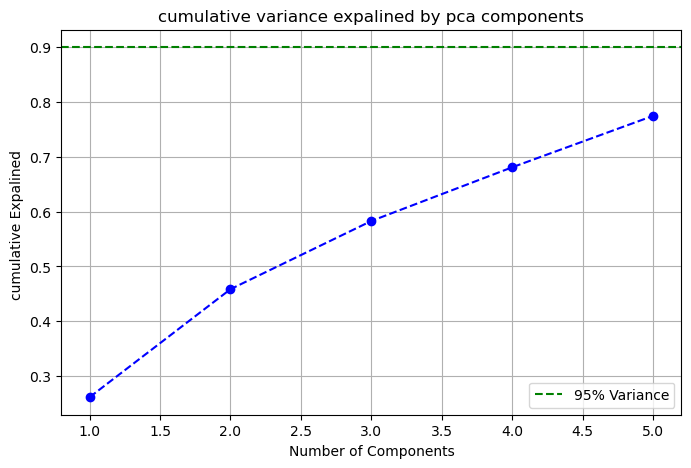

In [8]:
# plot cumulative variance
plt.figure(figsize=(8,5))
plt.plot(range(1,len(cumulative_variance)+1),cumulative_variance,marker='o',ls='--',color='b')
plt.title('cumulative variance expalined by pca components')
plt.xlabel('Number of Components')
plt.ylabel('cumulative Expalined ')
plt.axhline(y=0.9,color='g',ls='--',label='95% Variance')
plt.legend()
plt.grid(True)
plt.show();


In [ ]:
# print variance info
print('explained_variance ratio: ')
print(explained_variance.round(3))
print('\nCumulative Variance:')
print(cumulative_variance.round(3))


In [ ]:
loadings=pd.DataFrame(
    pca.components_.T,columns=[f'pc{i+1}' for i in range(pca.n_components_)],index=numeric_cols.columns
)
print('\nFeature Loadinges: ',loadings.round(3))


In [10]:
# use principal components for Logistic Regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [11]:
index_of_95=np.argmax(cumulative_variance>=0.95)
# np.arg max returns index of the first true. if no true is found it returns  0. we must check if 95% target was actually reached at the index
if cumulative_variance[index_of_95]>=0.95:
    # if reached n_opt is the index+1
    nopt=index_of_95+1
else:
    n_opt=len(explained_variance)
print(n_opt)


5


In [12]:
# use the optimally reduced data for modeling
X_pca_reduced=data_pca[:, :n_opt]
y=df['Outcome']


In [14]:
X_train,X_test,y_train,y_test=train_test_split(X_pca_reduced,y,test_size=0.3,random_state=42,stratify=y)
log_reg=LogisticRegression(max_iter=1000)
log_reg.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [16]:
y_pred=log_reg.predict(X_test)

In [17]:
from nltk.chunk.util import accuracy
accuracy=accuracy_score(y_test,y_pred)
print(f'Model Accuracy: {accuracy:.4f}')

Model Accuracy: 0.9740
